[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture5_notebook.ipynb)

# Blockchain Applications — Lecture 5: Stablecoins II: De-pegging Pressure Index and Portfolios

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

Lecture 4 watched one pool. Can we measure pressure on the *whole* stablecoin system in one number, and is that number useful?
This notebook reproduces the estimates, tables and charts of Lecture 5:

1. comparing tokens with different anchors: reference-adjusted deviations and peg quality;
2. quantile regression and the least absolute shrinkage and selection operator (Lasso);
3. the De-pegging Pressure Index (DPI): construction, regimes and event responses;
4. inside the tail links: who is linked to whom, and how sparse the models become under pressure;
5. further material: a data check, a Shapley decomposition of the information blocks, and four long-only portfolio rules.

Main source: Fan, Sha, Härdle & Pele (2026), *Reference-adjusted Quantile Lasso reveals regime-dependent stablecoin depegging pressure* (draft), based on Fan (2026), MSc thesis, HU Berlin.
The idea of using a selected penalty as a risk measure comes from the Financial Risk Meter (FRM) of [Mihoci, Althof, Chen & Härdle (2020)](https://doi.org/10.1108/S0731-905320200000042016).
Results marked "paper" are typed in from the paper; every other number is estimated here.

Data: daily closes from EOD Historical Data (EODHD) for 10 stablecoins, the euro and gold, and four market variables, 1 January 2020 – 23 October 2026.
One basis point (bp) is 0.01%.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_5'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

## Setup: packages, chart style and data

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Data

Ten stablecoins: Tether (USDT), USD Coin (USDC), Dai (DAI), TrueUSD (TUSD), Pax Dollar (USDP), Gemini Dollar (GUSD), Binance USD (BUSD), Synthetix USD (sUSD), Pax Gold (PAXG, one troy ounce of gold) and STASIS Euro (EURS).
The paper also uses the Rupiah Token (IDRT), which has no EODHD data after September 2023.
Market variables: the US dollar index (DXY), the CBOE volatility index (VIX), the Standard & Poor's 500 index (S&P 500) and the 1-year US Treasury yield.

Prices are put on a calendar of all days; a missing close is filled from the past for at most 7 days.
**Data check** (as in Lecture 1): a daily move beyond 1,000 bp that reverses by at least 90% the next day is treated as a recording error; the close is set to missing and filled from the past. The flagged prints are listed in the further material at the end.

In [4]:
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy.optimize import linprog, minimize
from joblib import Parallel, delayed
import matplotlib

END = '2026-10-23'                           # last day of the lecture sample
END_PAPER = '2026-05-31'                     # last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def finish_fig(fig, name, ncol=3, bottom=0.12):
    """Legend below the plot, room for it, then save and show."""
    legend_below(fig, ncol=ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': daily('EURUSD.FOREX', END), 'PAXG': daily('XAUUSD.FOREX', END)}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)                                        # bad prints
FLAGS = pd.DataFrame([(c, t_.date(), P.loc[t_, c], lr.loc[t_, c]) for t_, c in bad.stack()[bad.stack()].index],
                     columns=['coin', 'date', 'close (USD)', 'log return (bp)'])
P = P.mask(bad).ffill(limit=7)
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)                                       # changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {len(FLAGS)}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


## 1. Comparing different anchors

### Reference adjustment

Not every stablecoin targets the dollar: EURS tracks the euro (EUR) and PAXG one ounce of gold (XAU).
Let $P_{i,t}$ be the dollar price of token $i$ and $B_{i,t}$ the dollar value of its reference asset. The reference-adjusted deviation and return, in bp, are

$$ d_{i,t} = 10^4\left(\frac{P_{i,t}}{B_{i,t}} - 1\right), \qquad r_{i,t} = 10^4\,\Delta \ln\frac{P_{i,t}}{B_{i,t}}, $$

with $B = 1$ for dollar tokens, EUR/USD for EURS and XAU/USD for PAXG. Without the adjustment, a 1% move of the euro would look like a 100 bp "depeg" of EURS.
Worked example: EURS at 1.1194 USD while EUR/USD = 1.1202.

In [5]:
print(f'EURS reference-adjusted deviation: 10^4 (1.1194 / 1.1202 - 1) = {1e4 * (1.1194 / 1.1202 - 1):.1f} bp')
D = 1e4 * (P / Bm - 1)                       # reference-adjusted signed deviation, bp
R = 1e4 * np.log(P / Bm).diff()              # reference-adjusted log return, bp

EURS reference-adjusted deviation: 10^4 (1.1194 / 1.1202 - 1) = -7.1 bp


### Peg quality, 2020 – May 2026

For each coin: the median absolute deviation $|d|$, the 5% quantile of $d$, and the share of days with $d \leq -100$ bp (a discount of at least 1%), over the paper's sample period.

In [6]:
Q = pd.DataFrame({c: {'median |d| (bp)': D[c].loc[:END_PAPER].dropna().abs().median(),
                      '5% quantile of d (bp)': D[c].loc[:END_PAPER].dropna().quantile(0.05),
                      '% days d <= -100 bp': 100 * (D[c].loc[:END_PAPER].dropna() <= -100).mean(),
                      'days': D[c].loc[:END_PAPER].notna().sum()} for c in COINS}).T
Q['paper: median |d| (bp)'] = pd.Series({'USDC': 4.11, 'DAI': 7.06, 'USDT': 5.37, 'USDP': 7.63})
Q.sort_values('median |d| (bp)').round(2)

,median |d| (bp),5% quantile of d (bp),% days d <= -100 bp,days,paper: median |d| (bp)
USDC,1.32,-5.00,0.17,2343.0,4.11
DAI,2.80,-8.98,0.68,2343.0,7.06
USDT,3.55,-11.25,0.09,2343.0,5.37
BUSD,3.67,-8.64,0.09,2343.0,NaN
USDP,7.29,-47.47,0.21,2343.0,7.63
TUSD,7.75,-37.78,2.09,2343.0,NaN
GUSD,17.70,-109.99,6.32,2343.0,NaN
PAXG,43.01,-123.97,9.22,2343.0,NaN
EURS,50.95,-251.88,17.06,2315.0,NaN
SUSD,56.32,-1883.38,25.99,2343.0,NaN


There are two tiers: the large dollar tokens stay within a few bp, while small, non-dollar or crypto-collateralised tokens are tens of bp off, with deep lower tails.
The data source matters for the levels (EODHD medians are lower than those of CoinGecko used in the paper), not for the ranking.

### Two tiers of peg quality

Distribution of $|d_{i,t}|$, January 2020 – May 2026, coins ordered by their median, log scale.

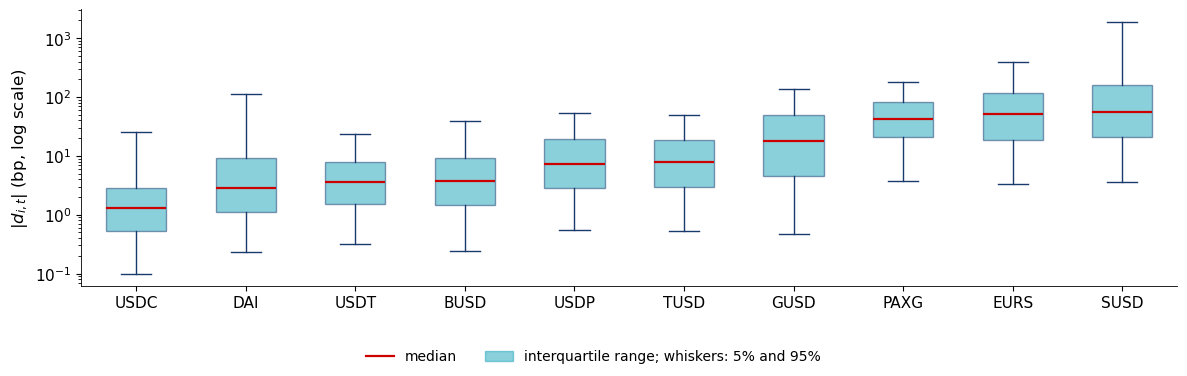

95% quantile of |d| (bp): {'USDC': 26.0, 'DAI': 114.0, 'USDT': 23.0, 'BUSD': 39.0, 'USDP': 54.0, 'TUSD': 49.0, 'GUSD': 139.0, 'PAXG': 182.0, 'EURS': 401.0, 'SUSD': 1883.0}


In [7]:
Dp = D.loc[:END_PAPER]
order = Dp.abs().median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 3.8))
bp_ = ax.boxplot([Dp[c].dropna().abs().clip(lower=0.1).values for c in order], whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55)
for b in bp_['boxes']:
    b.set(facecolor=TEAL, alpha=0.5, edgecolor=BLUE)
for k in ['whiskers', 'caps']:
    for l in bp_[k]:
        l.set(color=BLUE)
for l in bp_['medians']:
    l.set(color=RED, lw=1.6)
ax.set_yscale('log'); ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order)
ax.set_ylabel(r'$|d_{i,t}|$ (bp, log scale)')
ax.plot([], [], color=RED, lw=1.6, label='median')
ax.fill_between([], [], color=TEAL, alpha=0.5, label='interquartile range; whiskers: 5% and 95%')
finish_fig(fig, 'ba_l5_pegquality', ncol=2, bottom=0.12)
print('95% quantile of |d| (bp):', Dp.abs().quantile(0.95)[order].round(0).to_dict())

The 95% whisker spans three orders of magnitude, from about 25 bp for USDC to almost 2,000 bp for sUSD.

### A persistent depeg: sUSD

sUSD is collateralised by crypto assets in the Synthetix protocol. Its daily close since July 2024:

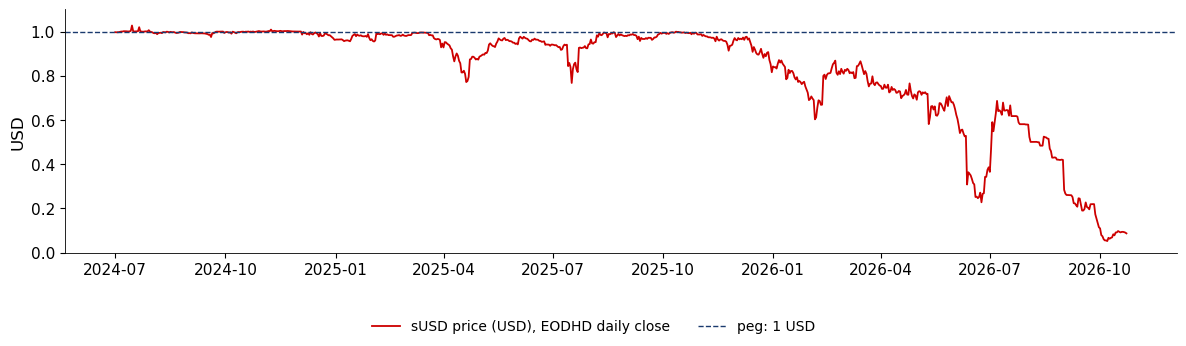

days below 0.99 USD since 1 January 2025: 607 of 661
first day below 0.95 USD after September 2025: 2025-11-24
sUSD close at quarter ends (USD): {'2025-03-31': 0.946, '2025-06-30': 0.941, '2025-09-30': 0.991, '2025-12-31': 0.816, '2026-03-31': 0.756, '2026-06-30': 0.386, '2026-09-30': 0.115, '2026-12-31': 0.088}
sUSD close on 2026-10-23: 0.09 USD


In [8]:
s = (1 + D['SUSD'] / 1e4).loc['2024-07-01':]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(s.index, s, color=RED, lw=1.3, label='sUSD price (USD), EODHD daily close')
ax.axhline(1, color=BLUE, ls='--', lw=1, label='peg: 1 USD')
ax.set_ylabel('USD'); ax.set_ylim(0, 1.1)
finish_fig(fig, 'ba_l5_susd', ncol=2, bottom=0.14)
s25 = s.loc['2025-01-01':]
print(f'days below 0.99 USD since 1 January 2025: {int((s25 < 0.99).sum())} of {len(s25)}')
print('first day below 0.95 USD after September 2025:', s.loc['2025-09-01':][s.loc['2025-09-01':] < 0.95].index[0].date())
print('sUSD close at quarter ends (USD):', {str(k.date()): round(v, 3) for k, v in P['SUSD'].resample('QE').last().loc['2025':].items()})
print(f'sUSD close on {s.index[-1].date()}: {s.iloc[-1]:.2f} USD')

Unlike the SVB weekend of Lecture 4 (two days), no arbitrage closes this gap, because redemption at par is not available: a depeg can be a slow default.

## 2. Quantile regression and the Lasso

### The check loss

The $\tau$-quantile minimises an asymmetric absolute loss ([Koenker & Bassett, 1978](https://doi.org/10.2307/1913643)):

$$ \rho_\tau(e) = e\,\big(\tau - \mathbb 1\{e < 0\}\big), \qquad q_\tau = \arg\min_q E\,\rho_\tau(Y - q). $$

Quantile regression solves $\min_{\alpha, \beta} \sum_i \rho_\tau(y_i - \alpha - \mathbf x_i'\beta)$, a linear programme.
For $\tau = 0.05$ a residual below the line costs $0.95|e|$ and one above it $0.05|e|$, so the fit is pushed to the lower tail.

Left: the check loss for three levels $\tau$. Right: the total loss $\sum_i \rho_\tau(y_i - q)$ of 20 daily deviations as a function of the candidate quantile $q$.

tau = 0.05: a minimiser of the total loss is q = -117.9 bp, minimum loss 116.55
tau = 0.5: a minimiser of the total loss is q = 2.0 bp, minimum loss 137.50


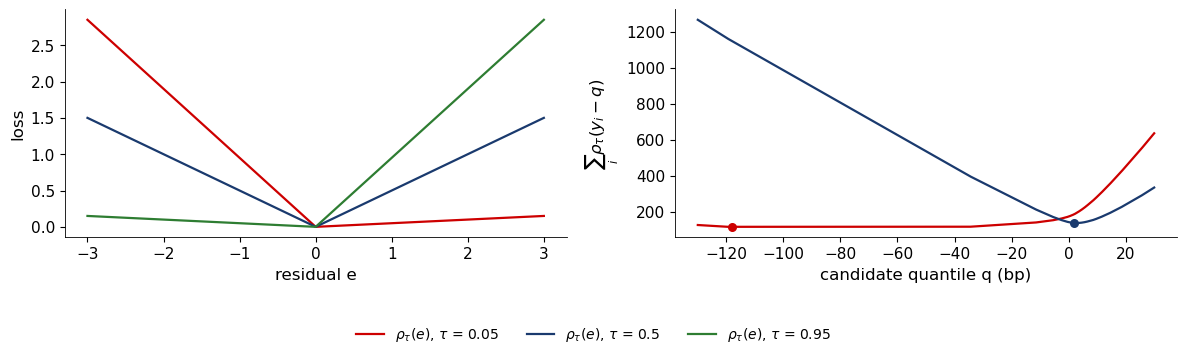

In [9]:
TAU = 0.05
check = lambda e, t: e * (t - (e < 0))
y20 = np.array([-120, -35, -12, -6, -3, -1, 0, 1, 2, 2, 3, 4, 5, 6, 8, 9, 11, 14, 18, 25])     # 20 daily deviations, bp
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
e = np.linspace(-3, 3, 400)
for t, col in [(0.05, RED), (0.5, BLUE), (0.95, GREEN)]:
    ax[0].plot(e, check(e, t), color=col, lw=1.6, label=fr'$\rho_\tau(e)$, $\tau$ = {t}')
ax[0].set_xlabel('residual e'); ax[0].set_ylabel('loss')
qgrid = np.linspace(-130, 30, 1601)
for t, col in [(0.05, RED), (0.5, BLUE)]:
    Lq = np.array([check(y20 - q, t).sum() for q in qgrid])
    ax[1].plot(qgrid, Lq, color=col, lw=1.6)
    k = np.argmin(Lq)
    ax[1].scatter([qgrid[k]], [Lq[k]], color=col, s=30, zorder=5)
    print(f'tau = {t}: a minimiser of the total loss is q = {qgrid[k]:.1f} bp, minimum loss {Lq[k]:.2f}')
ax[1].set_xlabel('candidate quantile q (bp)'); ax[1].set_ylabel(r'$\sum_i \rho_\tau(y_i - q)$')
finish_fig(fig, 'ba_l5_checkloss', ncol=3, bottom=0.15)

For $\tau = 0.5$ the minimum is the median (2 bp). For $\tau = 0.05$ the loss is *flat* between $-120$ and $-35$ bp.

### Worked example: how many points define a 5% quantile?

With $n = 20$ and $\tau = 0.05$, $n\tau = 1$: one observation lies below the quantile.

In [10]:
for q in [-120, -80, -35, -12]:
    print(f'total check loss at q = {q} bp: {check(y20 - q, 0.05).sum():.2f}')
print(f'n tau in a 90-day window: {90 * 0.05}')

total check loss at q = -120 bp: 116.55
total check loss at q = -80 bp: 116.55
total check loss at q = -35 bp: 116.55
total check loss at q = -12 bp: 139.55
n tau in a 90-day window: 4.5


Any value between the smallest and the second-smallest observation is a valid 5% quantile: the estimate is not unique.
In a 90-day window $n\tau = 4.5$, so four or five days carry the whole lower tail. Rolling 5% quantile models are noisy by construction: one day entering or leaving the window can move the estimate.
This is why the DPI is analysed in regimes and event windows, not day by day.

### Quantile Lasso and the selected penalty

With many candidate predictors we add an L1 penalty $\lambda\,\|\beta\|_1 = \lambda \sum_k |\beta_k|$ ([Tibshirani, 1996](https://doi.org/10.1111/j.2517-6161.1996.tb02080.x); [Belloni & Chernozhukov, 2011](https://doi.org/10.1214/10-AOS827)). For target coin $j$ and the window $W_t$ of the 90 days before day $t$:

$$ (\hat\alpha, \hat\beta)(\lambda) = \arg\min_{\alpha, \beta} \sum_{s \in W_t} \rho_{0.05}\big(d_{j,s} - \alpha - \mathbf x_{j,s}'\beta\big) + \lambda\,\|\beta\|_1 . $$

All slopes are zero for $\lambda \geq \lambda_{max}$, with $\psi_\tau(u) = \tau - \mathbb 1\{u < 0\}$ and

$$ \lambda_{max} = \max_k \Big|\sum_{s} x_{k,s}\,\psi_\tau\big(d_{j,s} - \hat q_\tau\big)\Big|, $$

a scaled covariance between each predictor and the target's lower-tail indicator. The penalty is chosen on a grid of 25 values from $10^{-4}\lambda_{max}$ to $\lambda_{max}$ by the generalised approximate cross-validation (GACV) criterion

$$ \mathrm{GACV}(\lambda) = \frac{\sum_s \rho_\tau\big(d_{j,s} - \hat\alpha - \mathbf x_{j,s}'\hat\beta(\lambda)\big)}{n - \mathrm{df}(\lambda)}, \qquad \mathrm{df} = \#\{\hat\beta_k \neq 0\} + 1, $$

where df are the degrees of freedom. The FRM idea: the selected $\hat\lambda_{j,t}$ is a risk measure; a higher $\hat\lambda$ means stronger tail co-movement under the fixed specification.

**Computation.** The Quantile Lasso is a linear programme. We solve its dual, which is smaller and gives the same solution:
$\max_z \mathbf y'z$ subject to $\mathbf 1'z = 0$, $|X'z| \leq \lambda$ and $\tau - 1 \leq z_s \leq \tau$; the slopes $\hat\beta$ and the intercept are the multipliers of the constraints.
Every variable is centred by its window median and divided by $1.4826 \times$ its median absolute deviation (MAD); the factor 1.4826 makes the MAD comparable to a standard deviation for Normal data.

In [11]:
WIN, NGRID, LO = 90, 25, 1e-4
DV, MV, MCOLS = D.values, M.values, list(M.columns)


def qlasso(X, y, lam, tau=TAU):
    """5% Quantile Lasso via the dual linear programme; returns intercept and slopes."""
    n, p = X.shape
    r = linprog(-y, A_ub=np.vstack([X.T, -X.T]), b_ub=np.full(2 * p, lam), A_eq=np.ones((1, n)), b_eq=[0],
                bounds=(tau - 1, tau), method='highs-ds')
    m = r.ineqlin.marginals
    return -r.eqlin.marginals[0], m[p:] - m[:p]


def robust(Z):
    """Centre by the median, scale by 1.4826 MAD (by the sd if the MAD is zero); drop constant columns."""
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    s = np.where(mad > 0, mad, Z.std(axis=0))
    keep = s > 0
    return (Z[:, keep] - med[keep]) / s[keep], keep


def fit_eq(y, X, lo=LO):
    """GACV-selected penalty: returns (lambda, GACV, slopes, index of lambda on the grid)."""
    n = len(y)
    if X.shape[1] == 0:
        return np.nan, check(y - np.quantile(y, TAU), TAU).sum() / (n - 1), np.array([]), -1
    q0 = np.quantile(y, TAU)
    lmax = np.abs(X.T @ (TAU - (y < q0))).max()
    best = None
    for k, lam in enumerate(np.geomspace(lmax * lo, lmax, NGRID)):
        a, b = qlasso(X, y, lam)
        df = 1 + (np.abs(b) > 1e-8).sum()
        g = check(y - a - X @ b, TAU).sum() / (n - df)
        if best is None or g < best[1]:
            best = (lam, g, b, k)
    return best


def day(t_idx, blocks=('coin', 'macro'), lo=LO):
    """All coin equations on the window of the 90 days before calendar row t_idx."""
    w = slice(t_idx - WIN, t_idx)
    out = {}
    for j, c in enumerate(COINS):
        y = DV[w, j]
        if np.isnan(y).any():
            continue
        y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))) or y.std() or 1)
        parts, names = [], []
        if 'coin' in blocks:
            others = [k for k in range(len(COINS)) if k != j]
            Xc = DV[w][:, others]
            ok = ~np.isnan(Xc).any(axis=0)
            parts.append(Xc[:, ok]); names += [COINS[k] for k, o in zip(others, ok) if o]
        if 'macro' in blocks:
            parts.append(MV[w]); names += MCOLS
        if parts:
            Zs, keep = robust(np.hstack(parts))
            names = [nm for nm, k in zip(names, keep) if k]
        else:
            Zs, names = np.empty((WIN, 0)), []
        lam, g, b, k = fit_eq(y, Zs, lo)
        out[c] = dict(lam=lam, gacv=g, k=k, coef=dict(zip(names, b)))
    return t_idx, out


N_JOBS = os.cpu_count() or 1


def days_chunk(ix, blocks, lo):
    return [day(i, blocks, lo) for i in ix]


def run_days(idx, blocks=('coin', 'macro'), lo=LO):
    """Estimate all equations on the calendar rows idx, in parallel on all cores (chunks of days per worker)."""
    chunks = [c for c in np.array_split(np.asarray(idx), 4 * N_JOBS) if len(c)]
    out = Parallel(n_jobs=N_JOBS)(delayed(days_chunk)(c, blocks, lo) for c in chunks)
    return {i: o for part in out for i, o in part}

### Worked example: one equation, USDC after SVB

Target USDC, window of the 90 days to 19 March 2023, 13 candidate predictors (9 coins and 4 lagged market changes). Left: the coefficient path $\hat\beta_k(\lambda)$ (solid: coins, dashed: market variables). Right: GACV and the number of active predictors.

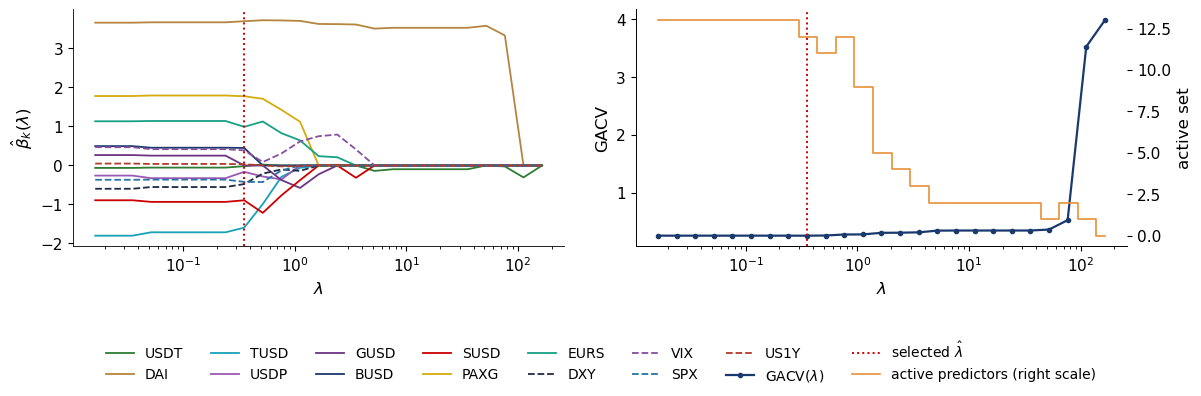

lambda_max = 164.1; selected lambda = 0.353 with 12 of 13 predictors active; minimum GACV = 0.2578


,slope at the selected lambda
DAI,3.698
PAXG,1.774
TUSD,-1.594
EURS,0.991
SUSD,-0.893
DXY,-0.477
BUSD,0.449
SPX,-0.420
VIX,0.387
USDP,-0.163


In [12]:
t_idx = cal.get_loc(pd.Timestamp('2023-03-20'))
w = slice(t_idx - WIN, t_idx)
j = COINS.index('USDC')
y = DV[w, j]
y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))))
names = [c for c in COINS if c != 'USDC'] + MCOLS
Zs, keep = robust(np.hstack([np.delete(DV[w], j, axis=1), MV[w]]))
names = [nm for nm, k in zip(names, keep) if k]
lmax = np.abs(Zs.T @ (TAU - (y < np.quantile(y, TAU)))).max()
grid = np.geomspace(lmax * LO, lmax, NGRID)
path, gac, dfs = [], [], []
for lam in grid:
    a, b = qlasso(Zs, y, lam)
    df = 1 + (np.abs(b) > 1e-8).sum()
    path.append(b); gac.append(check(y - a - Zs @ b, TAU).sum() / (len(y) - df)); dfs.append(df - 1)
path = np.array(path); kb = int(np.argmin(gac))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pal = [GREEN, GOLD, TEAL, ETH, '#6C3483', BLUE, RED, '#D4AC0D', '#16A085', NAVY, '#884EA0', '#2874A6', '#B03A2E']
for i, nm in enumerate(names):
    ax[0].plot(grid, path[:, i], color=pal[i % len(pal)], lw=1.3, ls='-' if nm in COINS else '--', label=nm)
ax[0].axvline(grid[kb], color=RED, ls=':', lw=1.4)
ax[0].set_xscale('log'); ax[0].set_xlabel(r'$\lambda$'); ax[0].set_ylabel(r'$\hat\beta_k(\lambda)$')
ax[1].plot(grid, gac, color=BLUE, lw=1.6, marker='o', ms=3, label=r'GACV($\lambda$)')
ax[1].axvline(grid[kb], color=RED, ls=':', lw=1.4, label=r'selected $\hat\lambda$')
ax2 = ax[1].twinx(); ax2.spines['top'].set_visible(False)
ax2.step(grid, dfs, color=BTC, where='mid', lw=1.2, label='active predictors (right scale)')
ax[1].set_xscale('log'); ax[1].set_xlabel(r'$\lambda$'); ax[1].set_ylabel('GACV'); ax2.set_ylabel('active set')
finish_fig(fig, 'ba_l5_lasso_path', ncol=8, bottom=0.2)
print(f'lambda_max = {lmax:.1f}; selected lambda = {grid[kb]:.3f} with {dfs[kb]} of {len(names)} predictors active; minimum GACV = {gac[kb]:.4f}')
pd.Series({nm: v for nm, v in zip(names, path[kb]) if abs(v) > 1e-8}).sort_values(key=abs, ascending=False).round(3).to_frame('slope at the selected lambda')

DAI enters first and stays up to the largest $\lambda$: in the SVB window, the lower tail of USDC was the lower tail of DAI.

## 3. The De-pegging Pressure Index

### Construction

For each coin $j$ and day $t$, a 5% Quantile Lasso on the preceding 90 days:

- target: $d_{j,s}$; predictors: the other coins' $d_{k,s}$ (same day) and the one-day-lagged changes of DXY, VIX, S&P 500 (log changes) and the 1-year yield (first differences); the paper also uses a crypto volatility index (CVIX);
- every variable centred by its window median and divided by $1.4826 \times \mathrm{MAD}$;
- 25 values of $\lambda$; $\hat\lambda_{j,t}$ minimises GACV.

The index is the average selected penalty:

$$ \mathrm{DPI}_t = \frac{1}{J}\sum_{j=1}^{J} \hat\lambda_{j,t} . $$

The DPI is *not* a depeg probability or a percentage; it is a model-implied measure of lower-tail dependence.

**Reduced computation.** The daily index from April 2020 to October 2026 needs about 24,000 equations, each on 25 penalties: some 600,000 linear programmes, which take more than half an hour on two processor cores.
Here we estimate the DPI **every 7th day** (the days before the weekly portfolio rebalancing used at the end), about 340 days, and **every day** only inside the windows around the six events analysed below.
The weekly series is enough for the chart, the annual medians and the trend; the event responses use daily values.
With two processor cores (as on Colab) the estimation cells below take about 5 minutes in total.
Set `FULL_DAILY = True` to estimate every day, as in the lecture.

In [13]:
import time
FULL_DAILY = False

EVENTS = {'KuCoin hack': '2020-09-26', 'China sell-off': '2021-05-19', 'Terra collapse': '2022-05-09',
          'FTX crisis': '2022-11-08', 'SVB / USDC depeg': '2023-03-11', 'Iran-Hormuz shock': '2026-02-28'}
first = cal.get_loc(pd.Timestamp('2020-04-01'))
weekly = [i for i in range(first, len(cal)) if (cal[i] - pd.Timestamp('2020-06-29')).days % 7 == 0]
ev_days = sorted({cal.get_loc(t_) for d0 in EVENTS.values()
                  for t_ in pd.date_range(pd.Timestamp(d0) - pd.Timedelta(days=60), pd.Timestamp(d0) + pd.Timedelta(days=30))})
idx = list(range(first, len(cal))) if FULL_DAILY else sorted(set(weekly) | set(ev_days))
t0 = time.time()
res = run_days(idx)
print(f'{len(idx)} days x {len(COINS)} coins estimated in {time.time() - t0:.0f} s')
LAM = pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in res.items()}).T[COINS].sort_index()
DPI_all = LAM.mean(axis=1)
DPI = DPI_all.loc[[cal[i] for i in weekly]] if not FULL_DAILY else DPI_all
print(f'DPI series used for the chart and trend: {len(DPI)} days, {DPI.index[0].date()} to {DPI.index[-1].date()}; median {DPI.median():.3f}')
print('annual medians of the DPI:', DPI.groupby(DPI.index.year).median().round(2).to_dict())

810 days x 10 coins estimated in 35 s
DPI series used for the chart and trend: 342 days, 2020-04-06 to 2026-10-19; median 0.384
annual medians of the DPI: {2020: 0.29, 2021: 0.42, 2022: 0.39, 2023: 0.37, 2024: 0.47, 2025: 0.56, 2026: 0.32}


### The DPI, April 2020 – October 2026

Points are coloured by the quintile of the DPI (the five 20% bands of its distribution, from "low" to "severe"); dotted lines mark the six events.

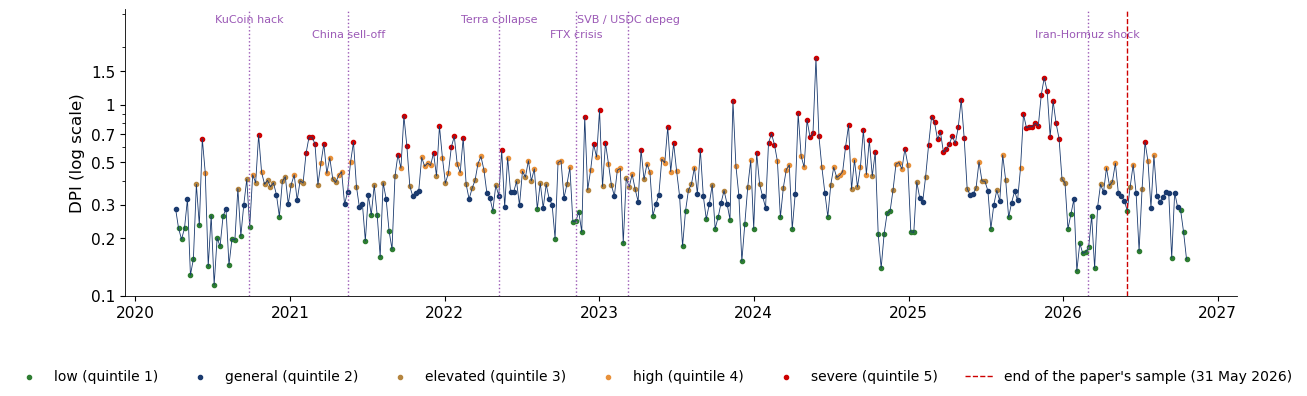

In [14]:
fig, ax = plt.subplots(figsize=(12, 4))
qs = DPI.quantile([0.2, 0.4, 0.6, 0.8]).values
cats = np.digitize(DPI.values, qs)
qcols = [GREEN, BLUE, GOLD, BTC, RED]; labs = ['low', 'general', 'elevated', 'high', 'severe']
ax.plot(DPI.index, DPI.values, color=BLUE, lw=0.6)
for k in range(5):
    m = cats == k
    ax.scatter(DPI.index[m], DPI.values[m], s=9, color=qcols[k], label=f'{labs[k]} (quintile {k + 1})')
for k_, (name, d0) in enumerate(EVENTS.items()):
    ax.axvline(pd.Timestamp(d0), color=ETH, ls=':', lw=1)
    ax.text(pd.Timestamp(d0), DPI.max() * (1.25 if k_ % 2 else 1.5), name, fontsize=8, color=ETH, ha='center', va='bottom')
ax.axvline(pd.Timestamp(END_PAPER), color=RED, ls='--', lw=1, label="end of the paper's sample (31 May 2026)")
ax.set_yscale('log'); ax.set_ylabel('DPI (log scale)'); ax.set_ylim(DPI.min() * 0.9, DPI.max() * 1.8)
ax.set_yticks([0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5])
ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter('%g')); ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
finish_fig(fig, 'ba_l5_dpi', ncol=6, bottom=0.14)

The DPI moves in regimes; its highest regime in late 2025 coincides with the start of the sUSD depeg.

Is there a secular trend? We regress $\ln \mathrm{DPI}_t$ on time in years up to May 2026 and use heteroskedasticity and autocorrelation consistent (HAC) standard errors (SE), with a lag window of about 90 days (13 weekly observations).

In [15]:
ld_ = np.log(DPI.loc[:END_PAPER])
tt = (ld_.index - ld_.index[0]).days.values / 365.25
lags = 90 if FULL_DAILY else 13
trd = sm.OLS(ld_.values, sm.add_constant(tt)).fit(cov_type='HAC', cov_kwds={'maxlags': lags})
print(f'trend of log DPI: {trd.params[1]:+.3f} per year (HAC SE {trd.bse[1]:.3f}, p-value {trd.pvalues[1]:.2f}); paper: -0.004 per year, p-value 0.78')

trend of log DPI: +0.049 per year (HAC SE 0.036, p-value 0.17); paper: -0.004 per year, p-value 0.78


The trend is not significant: regimes, no secular trend, as in the paper.

### Event responses

The response to an event is the change of the mean DPI over days 0 to 30 relative to days $-60$ to $-8$:

$$ \Delta = \overline{\mathrm{DPI}}_{[0, 30]} \big/ \overline{\mathrm{DPI}}_{[-60, -8]} - 1 . $$

The test regresses $\ln \mathrm{DPI}$ in the two windows on a post-event dummy, with HAC errors (30 lags); the Holm correction adjusts the six p-values for multiple testing.
To see how fragile these numbers are, we repeat the estimation with a narrower grid of penalties, $[10^{-2}, 1]\,\lambda_{max}$.

In [16]:
def responses(dpi):
    rows = {}
    for name, d0 in EVENTS.items():
        t0_ = pd.Timestamp(d0)
        pre = dpi.loc[t0_ - pd.Timedelta(days=60):t0_ - pd.Timedelta(days=8)]
        post = dpi.loc[t0_:t0_ + pd.Timedelta(days=30)]
        seg = np.log(pd.concat([pre, post]))
        dm = np.r_[np.zeros(len(pre)), np.ones(len(post))]
        fr = sm.OLS(seg.values, sm.add_constant(dm)).fit(cov_type='HAC', cov_kwds={'maxlags': 30})
        rows[name] = {'date': d0, 'change (%)': 100 * (post.mean() / pre.mean() - 1), 't-statistic': fr.tvalues[1], 'p-value': fr.pvalues[1]}
    out = pd.DataFrame(rows).T
    out['Holm p-value'] = multipletests(out['p-value'].astype(float), method='holm')[1]
    return out


DPI_ev = DPI_all.loc[[cal[i] for i in ev_days]]          # daily DPI inside the event windows
EV = responses(DPI_ev)
t0 = time.time()
res_n = run_days(ev_days, lo=1e-2)                       # narrow grid, same days
DPIn = pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in res_n.items()}).T[COINS].sort_index().mean(axis=1)
print(f'narrow grid estimated in {time.time() - t0:.0f} s')
EV['change, narrow grid (%)'] = responses(DPIn)['change (%)']
EV['paper: change (%)'] = pd.Series({'KuCoin hack': -14.4, 'China sell-off': -8.6, 'Terra collapse': 2.2, 'FTX crisis': 19.5,
                                     'SVB / USDC depeg': 11.0, 'Iran-Hormuz shock': -22.9})
EV.round(3)

narrow grid estimated in 22 s


,date,change (%),t-statistic,p-value,Holm p-value,"change, narrow grid (%)",paper: change (%)
KuCoin hack,2020-09-26,121.227213,10.376373,0.0,0.000,74.182724,-14.4
China sell-off,2021-05-19,-20.024841,-2.636948,0.008366,0.033,-11.841703,-8.6
Terra collapse,2022-05-09,18.136215,2.831535,0.004633,0.023,15.535518,2.2
FTX crisis,2022-11-08,13.523871,0.715972,0.474009,1.000,36.988539,19.5
SVB / USDC depeg,2023-03-11,6.168535,0.583313,0.559683,1.000,152.080147,11.0
Iran-Hormuz shock,2026-02-28,10.838295,0.676182,0.498925,1.000,-2.072911,-22.9


In the paper, the DPI rose significantly only after FTX and SVB, the two events about intermediation and reserve confidence (the paper's Terra response is not significant).
In this replication the sign agrees with the paper for 4 of the 6 events, but sizes and significance change with the data source and even with the grid of penalties.

### How robust are event responses?

event-window days: share of equations that select the smallest lambda (boundary solution): wide grid 8.8%, narrow grid 18.0%
correlation of log DPI, wide vs narrow grid, event-window days: 0.76


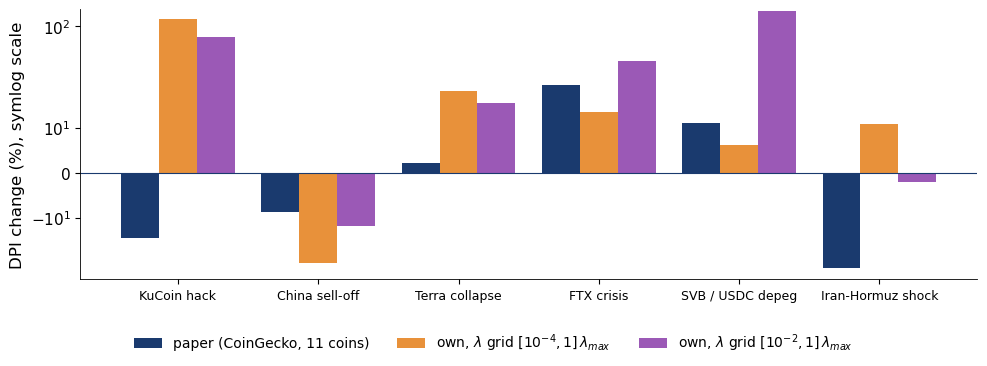

In [17]:
edge_w = np.mean([v['k'] == 0 for i in ev_days for v in res[i].values()])
edge_n = np.mean([v['k'] == 0 for o in res_n.values() for v in o.values()])
print(f'event-window days: share of equations that select the smallest lambda (boundary solution): wide grid {100 * edge_w:.1f}%, narrow grid {100 * edge_n:.1f}%')
print(f'correlation of log DPI, wide vs narrow grid, event-window days: {np.corrcoef(np.log(DPI_ev), np.log(DPIn))[0, 1]:.2f}')

fig, ax = plt.subplots(figsize=(10, 3.7))
xx = np.arange(len(EVENTS))
ax.bar(xx - 0.27, EV['paper: change (%)'].astype(float), width=0.27, color=BLUE, label='paper (CoinGecko, 11 coins)')
ax.bar(xx, EV['change (%)'].astype(float), width=0.27, color=BTC, label=r'own, $\lambda$ grid $[10^{-4}, 1]\,\lambda_{max}$')
ax.bar(xx + 0.27, EV['change, narrow grid (%)'].astype(float), width=0.27, color=ETH, label=r'own, $\lambda$ grid $[10^{-2}, 1]\,\lambda_{max}$')
ax.axhline(0, color=BLUE, lw=0.8)
ax.set_xticks(xx); ax.set_xticklabels(list(EVENTS), fontsize=9); ax.set_ylabel('DPI change (%), symlog scale')
ax.set_yscale('symlog', linthresh=20)                    # linear within +-20%, logarithmic beyond
finish_fig(fig, 'ba_l5_events', ncol=3, bottom=0.12)

With the narrow grid many more equations end at the smallest penalty, a boundary solution. The two indices are highly correlated, yet the SVB response is $+6\%$ in one specification and $+152\%$ in the other: a 31-day mean of a noisy index is sensitive to tuning choices.
Event responses should be reported together with their specification; results that survive several specifications deserve more trust.

## 4. Inside the tail links

### Who is linked to whom?

A positive slope is **aligned**: a lower deviation of the predictor coin goes with a lower 5% quantile of the target coin; a negative slope is **inverse**.
For each pair (target, predictor) we count how often the slope is aligned and how often inverse, over the weekly equations, and report the difference in percentage points (pp) of all equations of that target.

coin coefficients: aligned 47.2%, inverse 33.3% (paper: 39.6% and 23.9%)
market variables: 18.8% of the absolute slope weight (paper: 20.8%); mean active set 10.30 predictors


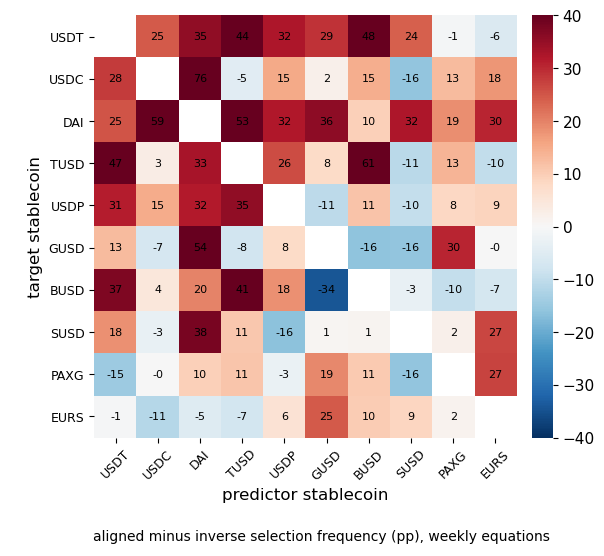

strongest aligned links (target <- predictor, pp): {'USDC <- DAI': 76, 'TUSD <- BUSD': 61, 'DAI <- USDC': 59, 'GUSD <- DAI': 54}
most inverse links (target <- predictor, pp): {'GUSD <- BUSD': -16, 'SUSD <- USDP': -16, 'BUSD <- GUSD': -34}


In [18]:
wres = {i: res[i] for i in weekly}
A = pd.DataFrame(0.0, index=COINS, columns=COINS); I_ = A.copy(); N_ = A.copy()
pos = neg = tot = 0
act, mac_w = [], []
for o in wres.values():
    for c, v in o.items():
        cf = v['coef']
        act.append(sum(abs(x) > 1e-8 for x in cf.values()))
        s_all = sum(abs(x) for x in cf.values())
        if s_all > 0:
            mac_w.append(sum(abs(cf.get(m, 0)) for m in MCOLS) / s_all)
        for k in COINS:
            if k == c:
                continue
            N_.loc[c, k] += 1
            x = cf.get(k, 0.0)
            A.loc[c, k] += x > 1e-8; I_.loc[c, k] += x < -1e-8
            if k in cf:
                tot += 1; pos += x > 1e-8; neg += x < -1e-8
Lk = 100 * (A - I_) / N_.replace(0, np.nan)
print(f'coin coefficients: aligned {100 * pos / tot:.1f}%, inverse {100 * neg / tot:.1f}% (paper: 39.6% and 23.9%)')
print(f'market variables: {100 * np.mean(mac_w):.1f}% of the absolute slope weight (paper: 20.8%); mean active set {np.mean(act):.2f} predictors')

fig, ax = plt.subplots(figsize=(8, 5.6))
im = ax.imshow(Lk.values, cmap='RdBu_r', vmin=-40, vmax=40)
for a in range(len(COINS)):
    for b in range(len(COINS)):
        if a != b:
            ax.text(b, a, f'{Lk.values[a, b]:.0f}', ha='center', va='center', fontsize=8)
ax.set_xticks(range(len(COINS))); ax.set_xticklabels(COINS, fontsize=9, rotation=45)
ax.set_yticks(range(len(COINS))); ax.set_yticklabels(COINS, fontsize=9)
ax.set_xlabel('predictor stablecoin'); ax.set_ylabel('target stablecoin')
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.outline.set_visible(False)
ax.plot([], [], color='none', label='aligned minus inverse selection frequency (pp), weekly equations')
finish_fig(fig, 'ba_l5_links', ncol=1, bottom=0.06)
top = Lk.stack().sort_values(ascending=False)
print('strongest aligned links (target <- predictor, pp):', {f'{a} <- {b}': round(v) for (a, b), v in top.head(4).items()})
print('most inverse links (target <- predictor, pp):', {f'{a} <- {b}': round(v) for (a, b), v in top.tail(3).items()})

Aligned links outnumber inverse ones, and the strongest pairs are economically plausible (USDC and DAI, which shared collateral; TUSD and BUSD).
In the paper no pair difference survives multiple testing, and the rankings change between the two halves of the sample: a common structure, with no fixed sender of pressure.

### Sparser models under pressure

The mean number of active predictors (out of 13) in each DPI quintile:

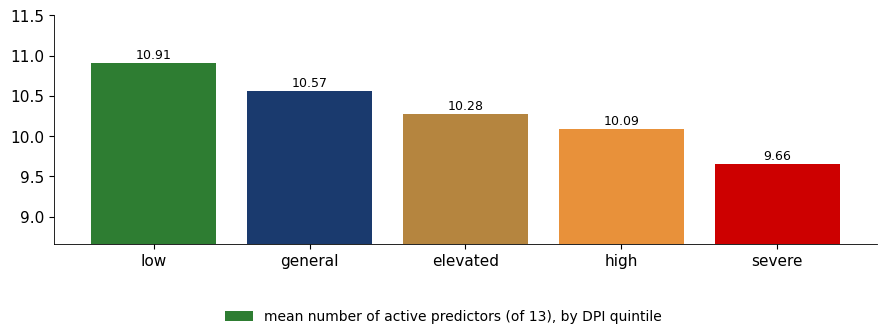

mean active set by DPI quintile: {'low': 10.91, 'general': 10.57, 'elevated': 10.28, 'high': 10.09, 'severe': 9.66} ; paper: 10.11 (lowest) to 9.00 (highest), of 15


In [19]:
act_day = pd.Series({cal[i]: np.mean([sum(abs(x) > 1e-8 for x in v['coef'].values()) for v in o.values()]) for i, o in wres.items()})
qd = pd.qcut(DPI, 5, labels=labs)
mq = act_day.reindex(DPI.index).groupby(qd).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(mq.index.astype(str), mq.values, color=qcols, label='mean number of active predictors (of 13), by DPI quintile')
for i, v_ in enumerate(mq.values):
    ax.text(i, v_ + 0.05, f'{v_:.2f}', ha='center', fontsize=9)
ax.set_ylim(mq.min() - 1, mq.max() + 0.6)
finish_fig(fig, 'ba_l5_active', ncol=1, bottom=0.14)
print('mean active set by DPI quintile:', mq.round(2).to_dict(), '; paper: 10.11 (lowest) to 9.00 (highest), of 15')

A higher penalty removes more predictors: under pressure, a few strong tail links dominate the equation. The direction is the same as in the paper, one of the results that survives replication.

### Fit is not forecast; concentration (paper)

Two further results of the paper need data that are not in the course repository (held-out forecasts with on-chain variables, market capitalisations), so we only report them:

| Model | conditional skill | same-day out-of-sample skill | fully lagged out-of-sample skill |
|---|---:|---:|---:|
| market variables only | 8.3% | −12.5% | −12.5% |
| coins only | 33.7% | −15.9% | −34.4% |
| joint | 37.0% | −19.8% | −38.6% |

Skill is the reduction of the held-out check loss relative to a rolling intercept-only model; a negative value means worse than that benchmark.
The best in-window description (joint, 37%) is the worst forecast once the predictors are dated $t-1$; the DPI alone has a negative out-of-sample (OOS) $R^2$ at horizons from 10 to 150 days.

The normalised Herfindahl–Hirschman index (HHI) of supply concentration has no significant link with the DPI once year effects are included: $+1$ standard deviation (SD) of the HHI goes with a $-1.52\%$ change of the DPI, 95% interval $[-4.24\%, 1.27\%]$.
Concentration tells you *how much* of the system depends on two issuers; it does not tell you *when* pressure builds.

## Further material

### Data check: bad prints

The prints removed by the rule in the data section, largest moves first:

In [20]:
FLAGS.assign(abs_move=FLAGS['log return (bp)'].abs()).sort_values('abs_move', ascending=False).drop(columns='abs_move').round(4).reset_index(drop=True)

,coin,date,close (USD),log return (bp)
0,SUSD,2025-08-06,0.2743,-12445.7368
1,EURS,2025-06-15,0.8788,-2719.6147
2,SUSD,2026-10-06,0.0724,2633.2439
3,EURS,2025-06-23,0.9362,-1953.1841
4,SUSD,2020-02-14,0.8372,-1566.2892
5,SUSD,2026-06-28,0.2961,-1471.9614
6,GUSD,2020-05-19,0.8965,-1086.4586
7,SUSD,2025-04-17,0.7313,-1084.3554
8,GUSD,2020-03-12,0.9060,-1023.3987


On 6 August 2025 sUSD closed at 0.27 USD and the next day at 0.98, on low volume. Left in the data, this single print would decide a portfolio comparison: one bad day can create a large drawdown on its own.

### Coins or market variables? A Shapley decomposition

The conditional skill of a model $m$ is $S_m = 1 - \overline{\mathrm{GACV}}_m / \overline{\mathrm{GACV}}_0$, where 0 is the intercept-only model and the bar averages over coins and days.
The two-block Shapley value of the coin block is

$$ \phi_{coin} = \tfrac12\big[(S_{coin} - S_0) + (S_{joint} - S_{macro})\big], \qquad \phi_{coin} + \phi_{macro} = S_{joint} . $$

We estimate the intercept-only, market-only and coins-only models on the weekly days; the joint model is the one already estimated for the DPI.

In [21]:
t0 = time.time()
blk = {'intercept only': run_days(weekly, ()), 'market variables only': run_days(weekly, ('macro',)),
       'coins only': run_days(weekly, ('coin',)), 'joint': wres}
print(f'block models estimated in {time.time() - t0:.0f} s')
G = {k: np.mean([np.mean([v['gacv'] for v in o.values()]) for o in r_.values()]) for k, r_ in blk.items()}
skill = {k: 100 * (1 - g / G['intercept only']) for k, g in G.items()}
Sm, Sc, Sj = skill['market variables only'], skill['coins only'], skill['joint']
phi_c = 0.5 * (Sc + (Sj - Sm)); phi_m = 0.5 * (Sm + (Sj - Sc))
print(f'Shapley share of the joint skill: coins {100 * phi_c / Sj:.1f}%, market variables {100 * phi_m / Sj:.1f}% (paper: coins 84.3%)')
pd.DataFrame({'mean GACV': G, 'conditional skill (%)': skill,
              'paper: mean GACV': {'intercept only': 0.1808, 'market variables only': 0.1658, 'coins only': 0.1199, 'joint': 0.1139}}).round(4)

block models estimated in 22 s
Shapley share of the joint skill: coins 88.7%, market variables 11.3% (paper: coins 84.3%)


,mean GACV,conditional skill (%),paper: mean GACV
intercept only,0.1669,0.0000,0.1808
market variables only,0.1564,6.3132,0.1658
coins only,0.1025,38.6105,0.1199
joint,0.0972,41.7562,0.1139


The stablecoin system explains its own lower tail; market variables add little. This result is robust across data sources.

### Four long-only rules

Consider an investor holding reference-adjusted stablecoin positions (a treasury, a market maker, a lending desk), with daily returns $r_{i,t}$ in bp.
The rules are rebalanced every 7 days with information up to $t-1$, and every weight is capped at 30%:

- equal weight: $w_i = 1/J$;
- global minimum variance (GMV): $\min_w w'\hat\Sigma w$ subject to $\sum w_i = 1$, $0 \leq w_i \leq 0.3$, with $\hat\Sigma$ the covariance matrix of the last 90 days, lightly shrunk to its diagonal;
- linear lambda: $\min_w \sum_i w_i \hat\lambda_{i,t-1}$ under the same constraints, i.e. fill the coins with the lowest penalty first;
- quadratic lambda (paper only): penalty level plus covariance.

Outcomes: annualised return and volatility, the 5% expected shortfall (ES, the mean of the worst 5% of daily returns, in bp), the maximum drawdown (max DD) and the turnover per rebalance.
The linear-lambda rule uses the penalties estimated above on the days before each rebalancing.

In [22]:
def run(end):
    """Weekly rebalanced long-only portfolios from 30 Jun 2020 to `end`."""
    Rr = R.loc['2020-06-30':end]
    days_ = Rr.index
    reb = set(days_[::7])
    rules = ['equal weight', 'global minimum variance', 'linear lambda']
    w_prev = {k: None for k in rules}
    W = {k: pd.DataFrame(0.0, index=days_, columns=COINS) for k in rules}
    turn = {k: [] for k in rules}
    cur = {}
    for t_ in days_:
        if t_ in reb:
            hist = R.loc[:t_ - pd.Timedelta(days=1)].iloc[-90:]
            avail = [c for c in COINS if hist[c].notna().all() and not np.isnan(P[c].loc[t_ - pd.Timedelta(days=1)])]
            n = len(avail)
            new = {'equal weight': pd.Series(1 / n, index=avail)}
            S = hist[avail].cov().values
            S = 0.9 * S + 0.1 * np.diag(np.diag(S))                  # light shrinkage to the diagonal
            Sn = S / np.median(np.diag(S))                            # rescale: variances differ by up to 1e6
            x0 = 1 / np.diag(Sn); x0 = np.minimum(x0 / x0.sum(), 0.3); x0 /= x0.sum()
            r_ = minimize(lambda w: w @ Sn @ w, x0, jac=lambda w: 2 * Sn @ w, bounds=[(0, 0.3)] * n,
                          constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP',
                          options={'ftol': 1e-12, 'maxiter': 500})
            new['global minimum variance'] = pd.Series(np.clip(r_.x, 0, None) / np.clip(r_.x, 0, None).sum(), index=avail)
            lam_ = LAM.loc[:t_ - pd.Timedelta(days=1)].iloc[-1].reindex(avail).fillna(np.inf)
            wl = pd.Series(0.0, index=avail); left = 1.0
            for c in lam_.sort_values().index:
                wl[c] = min(0.3, left); left -= wl[c]
                if left <= 1e-12:
                    break
            new['linear lambda'] = wl
            for k in new:
                wn = new[k].reindex(COINS).fillna(0)
                if w_prev[k] is not None:
                    turn[k].append(0.5 * (wn - w_prev[k]).abs().sum())
                w_prev[k] = wn
            cur = dict(w_prev)
        for k in cur:
            W[k].loc[t_] = cur[k]
    out, rets = {}, {}
    for k in W:
        rp = (W[k] * Rr.fillna(0)).sum(axis=1)                       # bp per day
        v_ = rp.values
        nav = np.exp(np.cumsum(v_ / 1e4))
        out[k] = {'return (% a year)': v_.mean() * 365 / 100, 'volatility (% a year)': v_.std() * np.sqrt(365) / 100,
                  'ES 5% (bp a day)': -v_[v_ <= np.quantile(v_, 0.05)].mean(),
                  'max drawdown (%)': 100 * (1 - nav / np.maximum.accumulate(nav)).max(),
                  'turnover per rebalance (%)': 100 * np.mean(turn[k])}
        rets[k] = rp
    return pd.DataFrame(out).T, W, pd.DataFrame(rets)


PT, Wp, _ = run(END_PAPER)
PT['paper: volatility (%)'] = [10.93, 3.14, 10.76]
PT['paper: ES 5% (bp)'] = [101.39, 39.03, 125.74]
PT['paper: max drawdown (%)'] = [15.6, 2.6, 16.5]
print('Portfolios, 30 Jun 2020 - 31 May 2026')
PT.round(2)

Portfolios, 30 Jun 2020 - 31 May 2026


,return (% a year),volatility (% a year),ES 5% (bp a day),max drawdown (%),turnover per rebalance (%),paper: volatility (%),paper: ES 5% (bp),paper: max drawdown (%)
equal weight,-0.81,3.93,49.39,7.63,0.06,10.93,101.39,15.6
global minimum variance,0.02,1.44,16.05,1.73,3.67,3.14,39.03,2.6
linear lambda,0.18,7.05,83.47,12.37,59.03,10.76,125.74,16.5


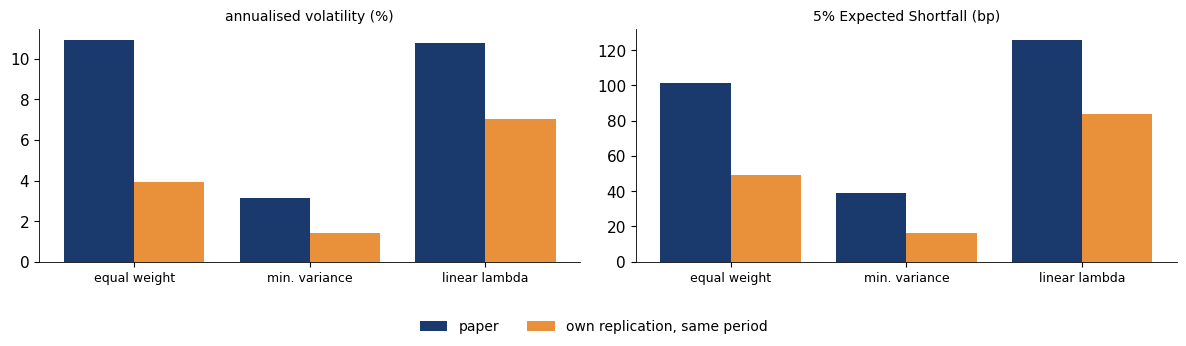

GMV against equal weight: volatility 63% lower, ES 67% lower (paper: 71% and 62%)


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
xx = np.arange(3)
for j_, (lab, col, pcol) in enumerate([('annualised volatility (%)', 'volatility (% a year)', 'paper: volatility (%)'),
                                       ('5% Expected Shortfall (bp)', 'ES 5% (bp a day)', 'paper: ES 5% (bp)')]):
    ax[j_].bar(xx - 0.2, PT[pcol].values, width=0.4, color=BLUE, label=('paper' if j_ == 0 else None))
    ax[j_].bar(xx + 0.2, PT[col].values, width=0.4, color=BTC, label=('own replication, same period' if j_ == 0 else None))
    ax[j_].set_xticks(xx); ax[j_].set_xticklabels(['equal weight', 'min. variance', 'linear lambda'], fontsize=9); ax[j_].set_title(lab, fontsize=10)
finish_fig(fig, 'ba_l5_portfolios', ncol=2, bottom=0.12)
ew_, gm_ = PT.loc['equal weight'], PT.loc['global minimum variance']
print(f'GMV against equal weight: volatility {100 * (1 - gm_.iloc[1] / ew_.iloc[1]):.0f}% lower, ES {100 * (1 - gm_.iloc[2] / ew_.iloc[2]):.0f}% lower (paper: 71% and 62%)')

Covariance beats penalties: GMV cuts volatility and ES by about two thirds against equal weight, while penalty-based weights add risk and turnover.

### Value and drawdown, 2020–2026

We extend the three rules to 23 October 2026, after the end of the paper's sample, when sUSD collapsed. Left: the value of 1 USD invested on 30 June 2020 (reference-adjusted returns); right: the drawdown from the running peak.

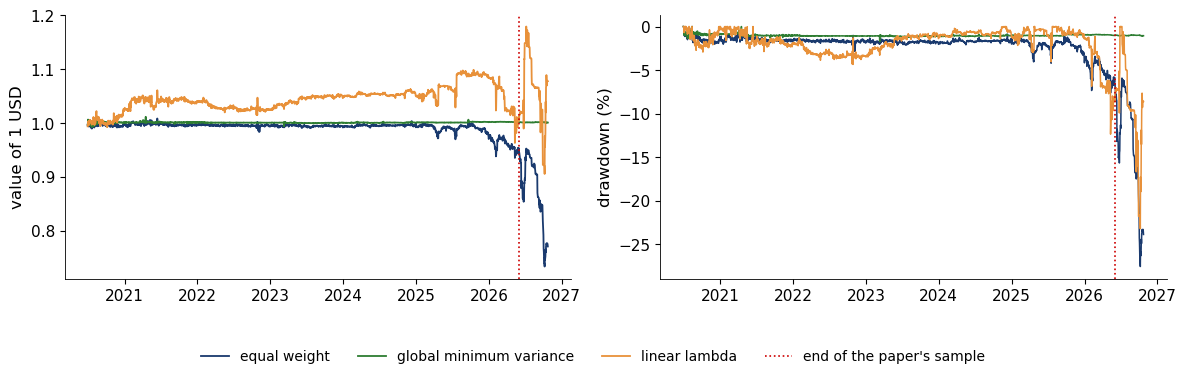

Portfolios, 30 Jun 2020 - 23 Oct 2026


,return (% a year),volatility (% a year),ES 5% (bp a day),max drawdown (%),turnover per rebalance (%)
equal weight,-4.13,6.02,76.88,27.58,0.06
global minimum variance,0.01,1.39,15.45,1.73,3.63
linear lambda,1.18,10.66,115.76,23.24,59.33


In [24]:
PT2, W2, PR = run(END)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
pcols = {'equal weight': BLUE, 'global minimum variance': GREEN, 'linear lambda': BTC}
for k, col in pcols.items():
    nav = np.exp(np.cumsum(PR[k] / 1e4))
    ax[0].plot(nav.index, nav, color=col, lw=1.3, label=k)
    ax[1].plot(nav.index, 100 * (nav / nav.cummax() - 1), color=col, lw=1.1)
for a in ax:
    a.axvline(pd.Timestamp(END_PAPER), color=RED, ls=':', lw=1.2)
ax[0].plot([], [], color=RED, ls=':', lw=1.2, label="end of the paper's sample")
ax[0].set_ylabel('value of 1 USD'); ax[1].set_ylabel('drawdown (%)')
finish_fig(fig, 'ba_l5_nav', ncol=4, bottom=0.14)
print('Portfolios, 30 Jun 2020 - 23 Oct 2026')
PT2.round(2)

GMV stays within about 2% of its peak over six years. Equal weight more than triples its drawdown once sUSD collapses, and linear lambda earns a little more in calm years and gives it back in stress: risk without a reliable reward.

### What the minimum-variance portfolio holds

Monthly averages of the GMV weights, June 2020 – May 2026:

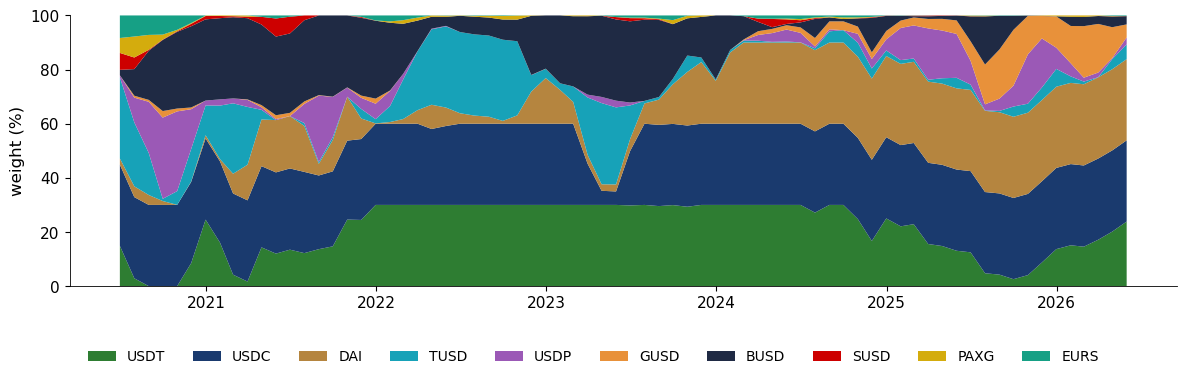

average GMV weights (%): {'USDC': 28.8, 'USDT': 21.1, 'DAI': 16.9, 'BUSD': 14.9, 'TUSD': 8.2, 'USDP': 5.2, 'GUSD': 3.1, 'EURS': 0.8, 'SUSD': 0.5, 'PAXG': 0.5}


In [25]:
gw = Wp['global minimum variance'].resample('ME').mean() * 100
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stackplot(gw.index, [gw[c] for c in COINS], labels=COINS,
             colors=[GREEN, BLUE, GOLD, TEAL, ETH, BTC, NAVY, RED, '#D4AC0D', '#16A085'])
ax.set_ylabel('weight (%)'); ax.set_ylim(0, 100)
finish_fig(fig, 'ba_l5_gmv_weights', ncol=10, bottom=0.12)
print('average GMV weights (%):', (100 * Wp['global minimum variance'].mean()).round(1).sort_values(ascending=False).to_dict())

The 30% cap binds often: without it GMV would hold even more USDC and USDT, that is, more issuer concentration.

### Worked example: why the penalty is a bad weight

$\hat\lambda_{j,t}$ is the regularisation chosen for one equation: it depends on how the *other* coins move in coin $j$'s lower tail, not on coin $j$'s own risk.
A small, erratic token (high variance, few co-movements) can get a *low* $\hat\lambda$ and then a 30% weight under the linear rule.
GMV, in contrast, reacts to the token's own variance. Before 12 June 2026, the 90-day standard deviation of daily returns was:

In [26]:
for c in ['SUSD', 'USDC']:
    print(f'{c}: 90-day sd of daily reference-adjusted returns before 12 June 2026 = {R[c].loc[:"2026-06-11"].iloc[-90:].std():.1f} bp')
print(f'GMV weight on sUSD on 11 June 2026: {100 * W2["global minimum variance"].loc["2026-06-11", "SUSD"]:.2f}%')
print(f'linear lambda: volatility {PT.loc["linear lambda", "volatility (% a year)"]:.1f}% a year vs {PT.loc["global minimum variance", "volatility (% a year)"]:.1f}% for GMV; '
      f'turnover {PT.loc["linear lambda", "turnover per rebalance (%)"]:.1f}% per week')

SUSD: 90-day sd of daily reference-adjusted returns before 12 June 2026 = 364.4 bp
USDC: 90-day sd of daily reference-adjusted returns before 12 June 2026 = 1.1 bp
GMV weight on sUSD on 11 June 2026: 0.04%
linear lambda: volatility 7.1% a year vs 1.4% for GMV; turnover 59.0% per week


The linear-lambda rule turns over more than half of the portfolio every week because the ranking of $\hat\lambda$ changes almost at every rebalancing, and it holds risky tokens whenever their tail links are weak.
GMV had already moved out of sUSD because its volatility had exploded, which is why it was protected when sUSD collapsed.